In [ ]:
import os
import pandas as pd
import datajoint as dj
# from datetime import datenid
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\_distributor_init.py:32: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.PYQHXLVVQ7VESDPUVUADXEVJOBGHJPAY.gfortran-win_amd64.dll
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.XWYDX2IKJW2NMTWSFYNGFUWKQU3LYTCZ.gfortran-win_amd64.dll
  stacklevel=1)


In [ ]:
from fig_params import *

fig_path = r''

### Data

In [ ]:
stim_types = ['EXPA', 'EXPA_60', 'EXPA_25', 'EXPW', 'EXPW_60','DIMM']

In [ ]:
from datajoint_utils import get_cluster_frs

sSC_dict = get_cluster_frs([], stim_types, dataset_name='sSC_VR_good_fr25_20260116', means=False, subsession_id='01', fix_sweeping=False)
dSC_dict = get_cluster_frs([], stim_types, dataset_name='dSC_VR_good_fr25_20260116', means=False, subsession_id='01', fix_sweeping=False)
LP_dict = get_cluster_frs([], stim_types, dataset_name='LP_VR_good_fr25_20260116', means=False, subsession_id='01', fix_sweeping=False)

sSC_frs, sSC_depths, sSC_keys_used = sSC_dict['cluster_frs'], sSC_dict['cluster_depths'], sSC_dict['cluster_keys']
dSC_frs, dSC_depths, dSC_keys_used = dSC_dict['cluster_frs'], dSC_dict['cluster_depths'], dSC_dict['cluster_keys']
LP_frs, LP_depths, LP_keys_used = LP_dict['cluster_frs'], LP_dict['cluster_depths'], LP_dict['cluster_keys']
sum([len(v) for k,v in sSC_frs.items()]), sum([len(v) for k,v in dSC_frs.items()]), sum([len(v) for k,v in LP_frs.items()])

sSC: 1414 , dSC: 1613 , LP: 782
Found data locally, loading...
Found data locally, loading...
Found data locally, loading...


(278, 498, 441)

In [11]:
print('sSC: ', len(sSC_keys_used), len(np.concatenate([val for key, val in sSC_keys_used.items()])))
print('dSC: ', len(dSC_keys_used), len(np.concatenate([val for key, val in dSC_keys_used.items()])))
print('LP: ', len(LP_keys_used), len(np.concatenate([val for key, val in LP_keys_used.items()])))

sSC:  23 262
dSC:  24 479
LP:  12 441


In [12]:
# Get means
for key in sSC_frs:
    sSC_frs[key] = np.nanmean(sSC_frs[key][:,:,:], axis=2)
    # baseline subtraction
    sSC_frs[key] = sSC_frs[key] - np.nanmean(sSC_frs[key][:,:,50:350], axis=2, keepdims=True)
for key in dSC_frs:
    dSC_frs[key] = np.nanmean(dSC_frs[key][:,:,:], axis=2)
    dSC_frs[key] = dSC_frs[key] - np.nanmean(dSC_frs[key][:,:,50:350], axis=2, keepdims=True)
for key in LP_frs:
    LP_frs[key] = np.nanmean(LP_frs[key][:,:,:], axis=2)
    LP_frs[key] = LP_frs[key] - np.nanmean(LP_frs[key][:,:,50:350], axis=2, keepdims=True)


### Code

In [18]:
def get_stim_idxs(stim, stim_types):
    return stim_types.index(stim)

In [ ]:


def get_stimcomp_df(compstims, windows):
    compstims_idxs = [get_stim_idxs(stim, stim_types) for stim in compstims]

    # Create dataframe with max median frs
    LP_df = pd.DataFrame(columns=compstims)
    sSC_df = pd.DataFrame(columns=compstims)
    dSC_df = pd.DataFrame(columns=compstims)

    for key, frs_curr in LP_frs.items():
        frs_curr = np.array(frs_curr)
        print(frs_curr.shape)
        for frs_curr_cluster in frs_curr:
            print(frs_curr_cluster.shape)
            LP_dict = {stim: np.percentile(frs_curr_cluster[stim_idx,start:end], 98) for stim_idx, stim, (start, end) in zip(compstims_idxs, compstims, windows)}
            LP_df = LP_df.append(LP_dict, ignore_index=True)
    for key, frs_curr in sSC_frs.items():
        frs_curr = np.array(frs_curr)
        for frs_curr_cluster in frs_curr:
            sSC_dict = {stim: np.percentile(frs_curr_cluster[stim_idx,start:end], 98) for stim_idx, stim, (start, end) in zip(compstims_idxs, compstims, windows)}
            sSC_df = sSC_df.append(sSC_dict, ignore_index=True)
    for key, frs_curr in dSC_frs.items():
        frs_curr = np.array(frs_curr)
        for frs_curr_cluster in frs_curr:
            dSC_dict = {stim: np.percentile(frs_curr_cluster[stim_idx,start:end], 98) for stim_idx, stim, (start, end) in zip(compstims_idxs, compstims, windows)}
            dSC_df = dSC_df.append(dSC_dict, ignore_index=True)

    print(LP_df)

    LP_df_norm = LP_df.div(np.max(LP_df, axis=1), axis=0)
    sSC_df_norm = sSC_df.div(np.max(sSC_df, axis=1), axis=0)
    dSC_df_norm = dSC_df.div(np.max(dSC_df, axis=1), axis=0)

    LP_df_norm = LP_df_norm.melt(var_name='stim', value_name='response')
    sSC_df_norm = sSC_df_norm.melt(var_name='stim', value_name='response')
    dSC_df_norm = dSC_df_norm.melt(var_name='stim', value_name='response')
    LP_df_norm['area'] = 'LP'
    sSC_df_norm['area'] = 'sSC'
    dSC_df_norm['area'] = 'dSC'

    all_df = pd.concat([LP_df_norm, sSC_df_norm, dSC_df_norm])

    return all_df


In [ ]:
constrast_stims = ['EXPW', 'EXPW_60', 'EXPA_25', 'EXPA_60', 'EXPA', 'DIMM']
contrast_stims_labels = ['expa white 100%', 'expa white 60%', 'expa black 25%', 'expa black 60%', 'expa black 100%', 'dimming']

windows = [(400, 400+100), (400, 400+100), (400, 400+100), (400, 400+100), (400, 400+100), (400, 400+100)]
all_df_contrast = get_stimcomp_df(constrast_stims, windows)


(6, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(7, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(10, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(70, 11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 2000)
(11, 20

In [17]:
cmap = sb.color_palette("tab10")
def get_percentiles(vec):
    return np.percentile(vec, [25, 75])

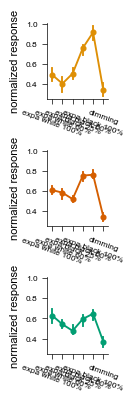

In [ ]:
# Separate plots for each brain area
# get rid of nan values
all_df_contrast = all_df_contrast.dropna()

fig, axs= plt.subplots(3, 1, figsize=(3.3*cm, 10*cm), sharey=True)
sb.pointplot(data=all_df_contrast[all_df_contrast['area']=='sSC'], x='stim', y='response', hue='area', ax=axs[0], palette=[colors[0]], estimator=np.median, errorbar='ci')
sb.pointplot(data=all_df_contrast[all_df_contrast['area']=='dSC'], x='stim', y='response', hue='area', ax=axs[1], palette=[colors[1]], estimator=np.median, errorbar='ci')
sb.pointplot(data=all_df_contrast[all_df_contrast['area']=='LP'], x='stim', y='response', hue='area', ax=axs[2], palette=[colors[2]], estimator=np.median, errorbar='ci')

for ax in axs:
    ax.set(xticklabels=contrast_stims_labels, xlabel='', ylabel='normalized response')
    plt.setp(ax.get_xticklabels(), rotation=-20)
    # axs[1].legend(bbox_to_anchor=(1, 1), frameon=False)
    ax.legend().set_visible(False)

plt.tight_layout()
# plt.savefig(rf'E:\KU Leuven\FarrowLab-Colab - VEIDB\Manuscript\Figures\Ephys\raw\Fig1\preferences_medianci.pdf', bbox_inches='tight', dpi=300)
plt.show()